In [11]:
!pip install pandas numpy matplotlib seaborn
!pip install nltk scikit-learn wordcloud
!pip install sqlalchemy pymysql
!pip install streamlit plotly


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import nltk
import re

from wordcloud import WordCloud

print("MediSense AI Project Started!")

MediSense AI Project Started!


In [13]:
df = pd.read_csv("hospital.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [14]:
df.head()

,Feedback,Sentiment Label,Ratings,Unnamed: 3
0,Good and clean hospital. There is great team o...,1,5,NaN
1,Had a really bad experience during discharge. ...,1,5,NaN
2,I have visited to take my second dose and Proc...,1,4,NaN
3,That person was slightly clueless and offered...,1,3,NaN
4,There is great team of doctors and good OT fac...,0,1,NaN


In [15]:
df.shape

(996, 4)

In [16]:
df.columns

Index(['Feedback', 'Sentiment Label', 'Ratings', 'Unnamed: 3'], dtype='object')

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 996 entries, 0 to 995
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Feedback         996 non-null    object 
 1   Sentiment Label  996 non-null    int64  
 2   Ratings          996 non-null    int64  
 3   Unnamed: 3       0 non-null      float64
dtypes: float64(1), int64(2), object(1)
memory usage: 31.2+ KB


In [18]:
df.isnull().sum()



Feedback             0
Sentiment Label      0
Ratings              0
Unnamed: 3         996
dtype: int64

In [19]:
df.duplicated().sum()

19

In [20]:
df.describe(include="all")

,Feedback,Sentiment Label,Ratings,Unnamed: 3
count,996,996.000000,996.000000,0.0
unique,951,NaN,NaN,NaN
top,This is our pleasure to inform you that it's a...,NaN,NaN,NaN
freq,2,NaN,NaN,NaN
mean,NaN,0.730924,3.567269,NaN
std,NaN,0.443703,1.408693,NaN
min,NaN,0.000000,1.000000,NaN
25%,NaN,0.000000,2.000000,NaN
50%,NaN,1.000000,4.000000,NaN
75%,NaN,1.000000,5.000000,NaN


In [21]:
df = df.drop(columns=["Unnamed: 3"])

df.head()

,Feedback,Sentiment Label,Ratings
0,Good and clean hospital. There is great team o...,1,5
1,Had a really bad experience during discharge. ...,1,5
2,I have visited to take my second dose and Proc...,1,4
3,That person was slightly clueless and offered...,1,3
4,There is great team of doctors and good OT fac...,0,1


In [22]:
df.isnull().sum()         #checking missing value

Feedback           0
Sentiment Label    0
Ratings            0
dtype: int64

In [23]:
print("Duplicate rows:", df.duplicated().sum())           #checking duplicate values

Duplicate rows: 19


In [24]:
df = df.drop_duplicates()                #removing duplicate rows

print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (977, 3)
Duplicate rows: 0


In [25]:
print(df["Sentiment Label"].unique())  #checking sentimental label         

[1 0]


In [26]:
df["Sentiment Label"].value_counts()

Sentiment Label
1    712
0    265
Name: count, dtype: int64

In [27]:
pd.set_option("display.max_colwidth", 200)          #check sample review

df[["Feedback", "Sentiment Label", "Ratings"]].sample(10)

,Feedback,Sentiment Label,Ratings
425,Good service by dilip kumar.,1,4
511,Worst Emergency service I have ever seen.,0,1
389,Dr Nishta performed my colposcopy and biopsy so effortlessly made me feel very comfortable.,1,4
811,Specialized care and expertise in nephrology and urology.,1,4
208,Aster hospital has the latest systems and techniques The hospital is very clean and well maintained.,1,4
687,it was hectic dealing with people at MANIPAL HEBBAL the doctors are amazing undoubtedly but before we reach the doctors we deal with these buffoons and this is troublesome.,1,3
509,I was very impressed with the Doctor and the staff was friendly and helpful I was able to get an appointment quickly.,1,5
148,One of the worst hospital my mother was admitted she was having ejection fraction of the heart of 35℅ but they gave false information saying 15℅ in the report and the cardiologist doctor venkatesh...,0,2
914,We deeply appreciate the fact that our community has access to such a high-quality organization of professionals and workers.,1,4
797,NU hospital provide excellent service for the patient They follow up everyday 3 to 4 times to the patient,1,5


In [28]:
df.groupby("Sentiment Label")["Ratings"].value_counts().sort_index()        #check ratings

Sentiment Label  Ratings
0                1          120
                 2          145
1                3          120
                 4          251
                 5          341
Name: count, dtype: int64

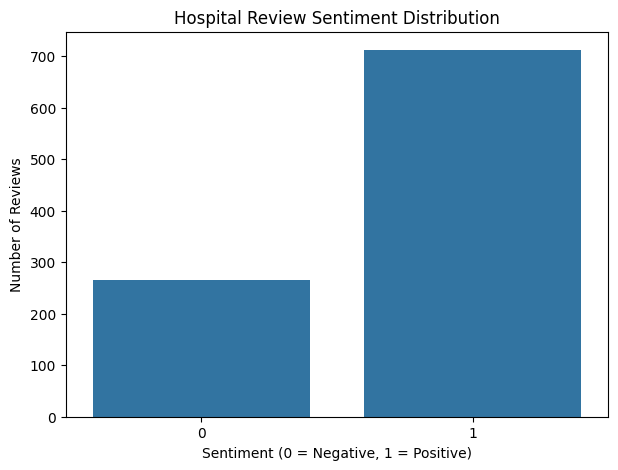

In [29]:
#create first EDA graph
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Sentiment Label"
)

plt.title("Hospital Review Sentiment Distribution")
plt.xlabel("Sentiment (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Reviews")

plt.show()

In [30]:
# calculate sentimental percentage

sentiment_percentage = (
    df["Sentiment Label"].value_counts(normalize=True) * 100
)

print(sentiment_percentage)

Sentiment Label
1    72.876151
0    27.123849
Name: proportion, dtype: float64


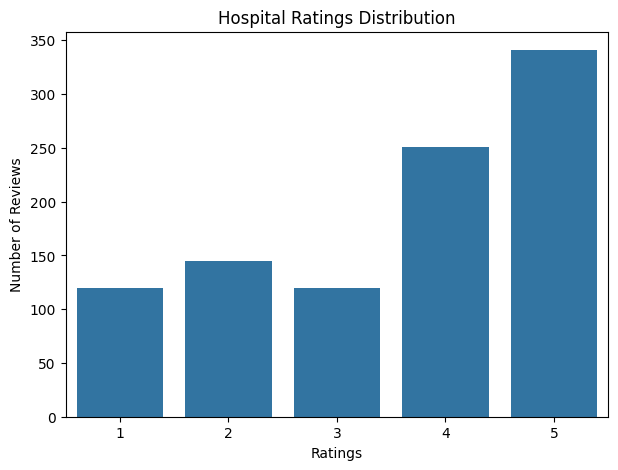

In [31]:
# next rating distribution graph

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Ratings")

plt.title("Hospital Ratings Distribution")
plt.xlabel("Ratings")
plt.ylabel("Number of Reviews")

plt.show()

In [32]:
# check avg rating

print("Average Rating:", df["Ratings"].mean())

Average Rating: 3.560900716479017


### Next step: Review text analysis (EDA)
### Now let's analyse the length of patient feedback.



In [33]:
#Step 1: Calculate review length

df["Review_Length"] = df["Feedback"].str.len()

df[["Feedback", "Review_Length"]].head()

,Feedback,Review_Length
0,"Good and clean hospital. There is great team of doctors and good OT facility. The medical facilities are all great with good in-patient post operative care by doctors, nurses. The housekeeping sta...",273
1,Had a really bad experience during discharge. They need to be sensitive and more transparent towards the patient and his/her family.,133
2,I have visited to take my second dose and Process was really smooth. Hospitality from all staffs are really appreciable. Shanti tooks good care and provide all details before vaccination. Thank you.,198
3,"That person was slightly clueless and offered only one package. But once i got to the hospital, I found a better and more economical one and decided to go ahead",161
4,There is great team of doctors and good OT facility.,52


In [34]:
#step 2: Find average review length
print("Average Review Length:", df["Review_Length"].mean())


Average Review Length: 118.73899692937565


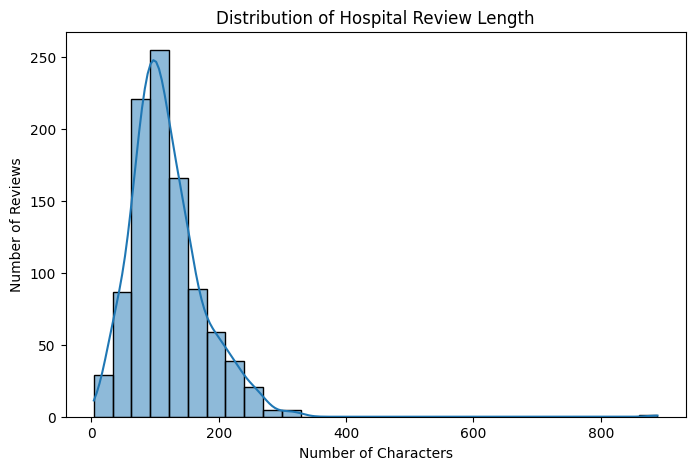

In [35]:
#Step 3: Create a graph

plt.figure(figsize=(8, 5))

sns.histplot(df["Review_Length"], bins=30, kde=True)

plt.title("Distribution of Hospital Review Length")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Reviews")

plt.show()

### Stage 2: NLP Text Preprocessing

In [36]:
#Create text cleaning function

def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

In [37]:
#Apply cleaning to Feedback column
df["Clean_Feedback"] = df["Feedback"].apply(clean_text)

In [38]:
#Compare original and cleaned reviews
df[["Feedback", "Clean_Feedback"]].head(10)

,Feedback,Clean_Feedback
0,"Good and clean hospital. There is great team of doctors and good OT facility. The medical facilities are all great with good in-patient post operative care by doctors, nurses. The housekeeping sta...",good and clean hospital there is great team of doctors and good ot facility the medical facilities are all great with good inpatient post operative care by doctors nurses the housekeeping staff is...
1,Had a really bad experience during discharge. They need to be sensitive and more transparent towards the patient and his/her family.,had a really bad experience during discharge they need to be sensitive and more transparent towards the patient and hisher family
2,I have visited to take my second dose and Process was really smooth. Hospitality from all staffs are really appreciable. Shanti tooks good care and provide all details before vaccination. Thank you.,i have visited to take my second dose and process was really smooth hospitality from all staffs are really appreciable shanti tooks good care and provide all details before vaccination thank you
3,"That person was slightly clueless and offered only one package. But once i got to the hospital, I found a better and more economical one and decided to go ahead",that person was slightly clueless and offered only one package but once i got to the hospital i found a better and more economical one and decided to go ahead
4,There is great team of doctors and good OT facility.,there is great team of doctors and good ot facility
5,"My primary concern arose from the insistence on conducting multiple tests, which appeared unrelated to my condition, before initiating any treatment.",my primary concern arose from the insistence on conducting multiple tests which appeared unrelated to my condition before initiating any treatment
6,"Good and clean hospital. The medical facilities are all great with good in-patient post operative care by doctors, nurses. The housekeeping staff is also good but they can respond to calls from t...",good and clean hospital the medical facilities are all great with good inpatient post operative care by doctors nurses the housekeeping staff is also good but they can respond to calls from the ro...
7,"Recently underwent a surgery for my left shoulder, the doctors are extremely good, but the management needs to be more patient oriented than money minded.",recently underwent a surgery for my left shoulder the doctors are extremely good but the management needs to be more patient oriented than money minded
8,"Over all experience was good, starting from reception,lab services and doctors interaction.Doctor with whom I have had consultation was so nice.He heard me with patience and clarified all my healt...",over all experience was good starting from receptionlab services and doctors interactiondoctor with whom i have had consultation was so nicehe heard me with patience and clarified all my health co...
9,"However,the services of front office (where we report first) need to be improved( services should be fast).",howeverthe services of front office where we report first need to be improved services should be fast


In [39]:
print(df.columns.tolist())

['Feedback', 'Sentiment Label', 'Ratings', 'Review_Length', 'Clean_Feedback']


### TOKENIZATION

In [40]:
df["Tokens"] = df["Clean_Feedback"].apply(lambda x: x.split())

df[["Clean_Feedback", "Tokens"]].head()

,Clean_Feedback,Tokens
0,good and clean hospital there is great team of doctors and good ot facility the medical facilities are all great with good inpatient post operative care by doctors nurses the housekeeping staff is...,"[good, and, clean, hospital, there, is, great, team, of, doctors, and, good, ot, facility, the, medical, facilities, are, all, great, with, good, inpatient, post, operative, care, by, doctors, nur..."
1,had a really bad experience during discharge they need to be sensitive and more transparent towards the patient and hisher family,"[had, a, really, bad, experience, during, discharge, they, need, to, be, sensitive, and, more, transparent, towards, the, patient, and, hisher, family]"
2,i have visited to take my second dose and process was really smooth hospitality from all staffs are really appreciable shanti tooks good care and provide all details before vaccination thank you,"[i, have, visited, to, take, my, second, dose, and, process, was, really, smooth, hospitality, from, all, staffs, are, really, appreciable, shanti, tooks, good, care, and, provide, all, details, b..."
3,that person was slightly clueless and offered only one package but once i got to the hospital i found a better and more economical one and decided to go ahead,"[that, person, was, slightly, clueless, and, offered, only, one, package, but, once, i, got, to, the, hospital, i, found, a, better, and, more, economical, one, and, decided, to, go, ahead]"
4,there is great team of doctors and good ot facility,"[there, is, great, team, of, doctors, and, good, ot, facility]"


### REMOVING STOPWORDS

In [41]:
import nltk

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\dell\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [42]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

# Keep negation words because they affect sentiment
stop_words = stop_words - {"not", "no", "nor"}

df["Processed_Feedback"] = df["Tokens"].apply(
    lambda words: " ".join(
        [word for word in words if word not in stop_words]
    )
)

df[["Clean_Feedback", "Processed_Feedback"]].head(10)

,Clean_Feedback,Processed_Feedback
0,good and clean hospital there is great team of doctors and good ot facility the medical facilities are all great with good inpatient post operative care by doctors nurses the housekeeping staff is...,good clean hospital great team doctors good ot facility medical facilities great good inpatient post operative care doctors nurses housekeeping staff also good respond calls room little faster
1,had a really bad experience during discharge they need to be sensitive and more transparent towards the patient and hisher family,really bad experience discharge need sensitive transparent towards patient hisher family
2,i have visited to take my second dose and process was really smooth hospitality from all staffs are really appreciable shanti tooks good care and provide all details before vaccination thank you,visited take second dose process really smooth hospitality staffs really appreciable shanti tooks good care provide details vaccination thank
3,that person was slightly clueless and offered only one package but once i got to the hospital i found a better and more economical one and decided to go ahead,person slightly clueless offered one package got hospital found better economical one decided go ahead
4,there is great team of doctors and good ot facility,great team doctors good ot facility
5,my primary concern arose from the insistence on conducting multiple tests which appeared unrelated to my condition before initiating any treatment,primary concern arose insistence conducting multiple tests appeared unrelated condition initiating treatment
6,good and clean hospital the medical facilities are all great with good inpatient post operative care by doctors nurses the housekeeping staff is also good but they can respond to calls from the ro...,good clean hospital medical facilities great good inpatient post operative care doctors nurses housekeeping staff also good respond calls room little faster
7,recently underwent a surgery for my left shoulder the doctors are extremely good but the management needs to be more patient oriented than money minded,recently underwent surgery left shoulder doctors extremely good management needs patient oriented money minded
8,over all experience was good starting from receptionlab services and doctors interactiondoctor with whom i have had consultation was so nicehe heard me with patience and clarified all my health co...,experience good starting receptionlab services doctors interactiondoctor consultation nicehe heard patience clarified health condition
9,howeverthe services of front office where we report first need to be improved services should be fast,howeverthe services front office report first need improved services fast


In [43]:
df.head()

,Feedback,Sentiment Label,Ratings,Review_Length,Clean_Feedback,Tokens,Processed_Feedback
0,"Good and clean hospital. There is great team of doctors and good OT facility. The medical facilities are all great with good in-patient post operative care by doctors, nurses. The housekeeping sta...",1,5,273,good and clean hospital there is great team of doctors and good ot facility the medical facilities are all great with good inpatient post operative care by doctors nurses the housekeeping staff is...,"[good, and, clean, hospital, there, is, great, team, of, doctors, and, good, ot, facility, the, medical, facilities, are, all, great, with, good, inpatient, post, operative, care, by, doctors, nur...",good clean hospital great team doctors good ot facility medical facilities great good inpatient post operative care doctors nurses housekeeping staff also good respond calls room little faster
1,Had a really bad experience during discharge. They need to be sensitive and more transparent towards the patient and his/her family.,1,5,133,had a really bad experience during discharge they need to be sensitive and more transparent towards the patient and hisher family,"[had, a, really, bad, experience, during, discharge, they, need, to, be, sensitive, and, more, transparent, towards, the, patient, and, hisher, family]",really bad experience discharge need sensitive transparent towards patient hisher family
2,I have visited to take my second dose and Process was really smooth. Hospitality from all staffs are really appreciable. Shanti tooks good care and provide all details before vaccination. Thank you.,1,4,198,i have visited to take my second dose and process was really smooth hospitality from all staffs are really appreciable shanti tooks good care and provide all details before vaccination thank you,"[i, have, visited, to, take, my, second, dose, and, process, was, really, smooth, hospitality, from, all, staffs, are, really, appreciable, shanti, tooks, good, care, and, provide, all, details, b...",visited take second dose process really smooth hospitality staffs really appreciable shanti tooks good care provide details vaccination thank
3,"That person was slightly clueless and offered only one package. But once i got to the hospital, I found a better and more economical one and decided to go ahead",1,3,161,that person was slightly clueless and offered only one package but once i got to the hospital i found a better and more economical one and decided to go ahead,"[that, person, was, slightly, clueless, and, offered, only, one, package, but, once, i, got, to, the, hospital, i, found, a, better, and, more, economical, one, and, decided, to, go, ahead]",person slightly clueless offered one package got hospital found better economical one decided go ahead
4,There is great team of doctors and good OT facility.,0,1,52,there is great team of doctors and good ot facility,"[there, is, great, team, of, doctors, and, good, ot, facility]",great team doctors good ot facility


  ### SATGE-3:TF-IDF Vectorization

In [44]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

In [45]:
# sep input and output
X = df["Processed_Feedback"]
y = df["Sentiment Label"]

In [46]:
# split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [47]:
# apply tf-idf
tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

In [48]:
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (781, 2140)
Testing data shape: (196, 2140)


### Stage 4: Machine Learning – Logistic Regression

In [49]:
# import logistic regression
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

In [50]:
# train the model
model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [51]:
# predict test data
y_pred = model.predict(X_test_tfidf)

print(y_pred[:10])

[1 1 1 1 1 0 1 1 1 1]


In [52]:
# evaluste model performance
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 82.6530612244898 %


In [53]:
# deatailed evaluation
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.40      0.55        53
           1       0.82      0.99      0.89       143

    accuracy                           0.83       196
   macro avg       0.86      0.69      0.72       196
weighted avg       0.84      0.83      0.80       196



### step 1:confusion matrix 

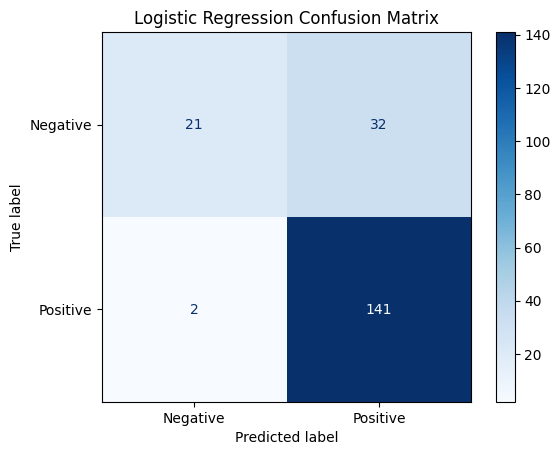

In [57]:


from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [58]:
print(X_test.shape)
print(y_test.shape)
print(y_pred.shape)

(196,)
(196,)
(196,)


### step 2:navies bayes

In [61]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

In [62]:
nb_model.fit(X_train_tfidf, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [63]:
nb_pred = nb_model.predict(X_test_tfidf)

print(nb_pred)

[1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0 1 1 1 1 0 1 1 1 0 1 1 1 1 1 1 1 1 0
 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1
 1 1 1 1 1 1 1 1 0 1 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1
 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1
 1 0 1 1 1 1 1 1 1 1 1]


In [64]:
from sklearn.metrics import accuracy_score, classification_report

nb_accuracy = accuracy_score(y_test, nb_pred)

print("Naive Bayes Accuracy:", nb_accuracy * 100, "%")

print(classification_report(y_test, nb_pred))

Naive Bayes Accuracy: 79.59183673469387 %
              precision    recall  f1-score   support

           0       0.88      0.28      0.43        53
           1       0.79      0.99      0.88       143

    accuracy                           0.80       196
   macro avg       0.84      0.63      0.65       196
weighted avg       0.81      0.80      0.75       196



### step 3: linear svm algm

In [65]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(class_weight="balanced")

svm_model.fit(X_train_tfidf, y_train)

,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1.0
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,verbose,0
,random_state,None


In [66]:
svm_pred = svm_model.predict(X_test_tfidf)

In [67]:
svm_accuracy = accuracy_score(y_test, svm_pred)

print("Linear SVM Accuracy:", svm_accuracy * 100, "%")

print(classification_report(y_test, svm_pred))

Linear SVM Accuracy: 86.22448979591837 %
              precision    recall  f1-score   support

           0       0.75      0.74      0.74        53
           1       0.90      0.91      0.91       143

    accuracy                           0.86       196
   macro avg       0.83      0.82      0.82       196
weighted avg       0.86      0.86      0.86       196



### Step 3: Confusion Matrix for Linear SVM

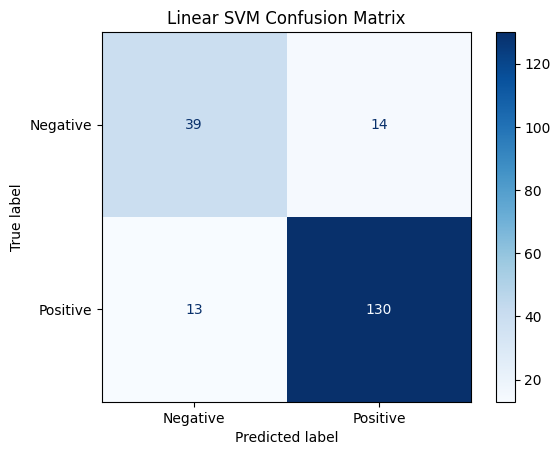

In [68]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

svm_cm = confusion_matrix(y_test, svm_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=svm_cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues")
plt.title("Linear SVM Confusion Matrix")
plt.show()

### Next step: Save our best model

In [69]:
import joblib                                  #medisense_model.pkl – stores our trained Linear SVM model.



tfidf_vectorizer.pkl – stores the text conversion process.

joblib.dump(svm_model, "medisense_model.pkl")

joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and Vectorizer saved successfully!")

Model and Vectorizer saved successfully!


### step: test with new hospital review



In [70]:
import joblib
import re
from nltk.corpus import stopwords

# Load saved model and vectorizer
loaded_model = joblib.load("medisense_model.pkl")
loaded_tfidf = joblib.load("tfidf_vectorizer.pkl")

# Preprocessing function
stop_words = set(stopwords.words("english"))
stop_words = stop_words - {"not", "no", "nor"}

def preprocess_review(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()

    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

# New hospital review
new_review = ["The doctors were very helpful and the hospital service was excellent"]

# Preprocess review
cleaned_review = [preprocess_review(new_review[0])]

# Convert text into TF-IDF
review_tfidf = loaded_tfidf.transform(cleaned_review)

# Predict sentiment
prediction = loaded_model.predict(review_tfidf)

if prediction[0] == 1:
    print("Predicted Sentiment: Positive 😊")
else:
    print("Predicted Sentiment: Negative")

Predicted Sentiment: Positive 😊


In [71]:
new_review = ["The hospital staff were rude and the treatment was very poor"]

cleaned_review = [preprocess_review(new_review[0])]

review_tfidf = loaded_tfidf.transform(cleaned_review)

prediction = loaded_model.predict(review_tfidf)

if prediction[0] == 1:
    print("Predicted Sentiment: Positive 😊")
else:
    print("Predicted Sentiment: Negative 😟")

Predicted Sentiment: Negative 😟


### Step 6: Install Streamlit

In [72]:
!pip install streamlit


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


 ### Step 7: Prepare our MediSense AI application

In [73]:
import os

print(os.getcwd())
print(os.listdir())



C:\Users\dell\Desktop\MEDISENSE AI
['.ipynb_checkpoints', 'hospital.csv', 'MediSense_AI.ipynb', 'medisense_model.pkl', 'tfidf_vectorizer.pkl']


### Step 8: Create app.py

In [ ]:
# What this code does
- Creates a MediSense AI webpage.
- Accepts a patient's hospital review.
- Cleans the review.
- Uses our saved ML model to predict sentiment.
- Displays Positive or Negative.

In [74]:
%%writefile app.py

import streamlit as st
import joblib
import re
import nltk
from nltk.corpus import stopwords

# Load saved model and vectorizer
model = joblib.load("medisense_model.pkl")
tfidf = joblib.load("tfidf_vectorizer.pkl")

# Stopwords
stop_words = set(stopwords.words("english"))
stop_words = stop_words - {"not", "no", "nor"}

# Text preprocessing
def preprocess_review(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()

    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

# Streamlit page
st.set_page_config(
    page_title="MediSense AI",
    page_icon="🏥"
)

st.title("🏥 MediSense AI")
st.subheader("Healthcare Review Intelligence System")

st.write(
    "Enter a hospital review below to predict its sentiment."
)

review = st.text_area("Enter Patient Review")

if st.button("Analyze Review"):

    if review.strip() == "":
        st.warning("Please enter a hospital review.")

    else:
        cleaned_review = preprocess_review(review)

        review_tfidf = tfidf.transform([cleaned_review])

        prediction = model.predict(review_tfidf)

        if prediction[0] == 1:
            st.success("Positive Review 😊")
        else:
            st.error("Negative Review 😟")

Writing app.py


### Step 9: Run the Streamlit application

In [78]:
!streamlit run app.py

^C


In [79]:
import os
print(os.getcwd())

C:\Users\dell\Desktop\MEDISENSE AI


### First, update your app.py

In [80]:
%%writefile app.py

import streamlit as st
import joblib
import re
from nltk.corpus import stopwords

# Page configuration
st.set_page_config(
    page_title="MediSense AI",
    page_icon="🏥",
    layout="wide"
)

# Load model
model = joblib.load("medisense_model.pkl")
tfidf = joblib.load("tfidf_vectorizer.pkl")

# Stopwords
stop_words = set(stopwords.words("english"))
stop_words = stop_words - {"not", "no", "nor"}

# Text preprocessing
def preprocess_review(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()

    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

# Custom CSS
st.markdown("""
<style>
.stApp {
    background-color: #f0f7f8;
}

.main-title {
    color: #087e8b;
    font-size: 42px;
    font-weight: bold;
    text-align: center;
}

.subtitle {
    color: #526777;
    text-align: center;
    font-size: 18px;
}

.review-box {
    background-color: white;
    padding: 25px;
    border-radius: 15px;
    border: 1px solid #d8e6e8;
}

</style>
""", unsafe_allow_html=True)

# Header
st.markdown(
    '<div class="main-title">🏥 MediSense AI</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="subtitle">Healthcare Review Intelligence System</div>',
    unsafe_allow_html=True
)

st.write("")
st.divider()

# Sidebar
with st.sidebar:
    st.title("🏥 MediSense AI")
    st.write("Healthcare Review Analysis")
    st.divider()
    st.subheader("About the Project")
    st.write(
        "MediSense AI uses Natural Language Processing "
        "and Machine Learning to analyze hospital reviews."
    )
    st.info("Algorithm: Linear Support Vector Machine")

# Main section
st.subheader("Patient Review Analysis")

st.write(
    "Enter a hospital patient review below to identify its sentiment."
)

review = st.text_area(
    "Enter Patient Review",
    placeholder="Example: The doctors were helpful and the treatment was excellent...",
    height=150
)

if st.button("🔍 Analyze Review", use_container_width=True):

    if review.strip() == "":
        st.warning("Please enter a hospital review.")

    else:
        cleaned_review = preprocess_review(review)
        review_tfidf = tfidf.transform([cleaned_review])
        prediction = model.predict(review_tfidf)

        st.divider()
        st.subheader("Analysis Result")

        if prediction[0] == 1:
            st.success("😊 Positive Review")
            st.write(
                "The model classified this hospital review as Positive."
            )

        else:
            st.error("😟 Negative Review")
            st.write(
                "The model classified this hospital review as Negative."
            )

st.divider()

st.caption(
    "MediSense AI | Machine Learning & NLP Based Healthcare Review Analysis"
)

Overwriting app.py
